## 기초데이터과학 (01분반)

## Lab 09. 상관 분석과 가설 검정 실습

### 진행 방식

- **문제 단위**로 진행하며, 문제마다 제한시간이 있음
- 코드 틀에서 `None` 으로 비어 있는 부분을 채우거나, 주석을 참고하여 코드를 작성할 것
- 실행 결과가 아래 **기대 출력**과 같으면 정답. 그래프는 종류, 축, 제목이 같으면 정답
- 제한시간이 끝나면 다 같이 풀이 진행

### 실습 내용

| 문제 | 내용 | 작성할 것 |
|---|---|---|
| 1 | 상관 행렬 해석하기 | 코드 + 결과 해석 |
| 2 | 이상치가 상관계수에 주는 영향 | 코드 + 결과 해석 |
| 3 | 순열 검정 직접 구현하기 | 코드 + 결과 해석 |
| 4 | 유의확률과 함께 확인해야 할 것 | 코드 + 결과 해석 |

In [ ]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from scipy import stats

---

## 실습 데이터: 포유류의 수면 (msleep)

- 포유류 83종의 수면 시간, 몸무게, 뇌 무게, 식성 자료
- 아래 셀을 먼저 실행할 것

| 변수 | 의미 |
|---|---|
| `name` | 동물 이름 |
| `vore` | 식성 (`carni` 육식, `herbi` 초식, `omni` 잡식, `insecti` 충식) |
| `sleep_total` | 하루 총 수면 시간 (시간) |
| `sleep_rem` | 렘수면 시간 (시간) |
| `sleep_cycle` | 수면 주기의 길이 (시간) |
| `awake` | 하루 중 깨어 있는 시간 (시간) |
| `brainwt` | 뇌 무게 (kg) |
| `bodywt` | 몸무게 (kg) |

In [1]:
msleep = pd.read_csv('msleep.csv')

print(msleep.shape)
print(msleep[['name', 'vore', 'sleep_total', 'awake', 'brainwt', 'bodywt']].head())

(83, 11)
                         name   vore  sleep_total  awake  brainwt   bodywt
0                     Cheetah  carni         12.1   11.9      NaN   50.000
1                  Owl monkey   omni         17.0    7.0  0.01550    0.480
2             Mountain beaver  herbi         14.4    9.6      NaN    1.350
3  Greater short-tailed shrew   omni         14.9    9.1  0.00029    0.019
4                         Cow  herbi          4.0   20.0  0.42300  600.000


---

## 문제 1. 상관 행렬 해석하기 (제한시간 8분)

#### 1-1. `sleep_total`, `sleep_rem`, `sleep_cycle`, `awake`, `brainwt`, `bodywt` 여섯 변수의 상관 행렬을 구하고 heatmap 으로 그리시오.

- 상관 행렬은 소수점 둘째 자리까지 반올림하여 `sleep_cor` 에 저장
- heatmap 에는 값을 표시하고, 색상은 `'RdBu'`, 색의 범위는 -1 ~ 1
- 제목은 `Correlation of Sleep Variables`

In [ ]:
cols = ['sleep_total', 'sleep_rem', 'sleep_cycle', 'awake', 'brainwt', 'bodywt']
sleep_cor = None     # TODO

# heatmap 그리기와 제목


print(sleep_cor)

**기대 출력**

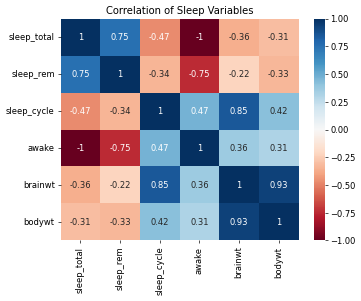

```
             sleep_total  sleep_rem  sleep_cycle  awake  brainwt  bodywt
sleep_total         1.00       0.75        -0.47  -1.00    -0.36   -0.31
sleep_rem           0.75       1.00        -0.34  -0.75    -0.22   -0.33
sleep_cycle        -0.47      -0.34         1.00   0.47     0.85    0.42
awake              -1.00      -0.75         0.47   1.00     0.36    0.31
brainwt            -0.36      -0.22         0.85   0.36     1.00    0.93
bodywt             -0.31      -0.33         0.42   0.31     0.93    1.00
```

#### 1-2. `sleep_total` 과 `awake` 의 상관계수가 -1.00 으로 나온 이유는 무엇인가?

> **힌트**
> - 두 변수를 더한 값을 확인해 볼 것

In [ ]:
# 힌트를 확인하는 코드 작성


---

##### 답안 (이 셀을 더블클릭하여 아래에 작성)

- 상관계수가 -1.00 인 이유:

---

## 문제 2. 이상치가 상관계수에 주는 영향 (제한시간 12분)

#### 2-1. 몸무게(`bodywt`)와 뇌 무게(`brainwt`)의 피어슨 상관계수와 스피어만 상관계수를 구하시오.

- 소수점 셋째 자리까지 반올림

In [ ]:
r_pearson  = None    # TODO
r_spearman = None    # TODO

print("피어슨:", r_pearson, " 스피어만:", r_spearman)

**기대 출력**

```
피어슨: 0.934  스피어만: 0.957
```

#### 2-2. 몸무게가 1,000kg 이상인 동물을 출력하고, 이 동물들을 제외한 뒤 두 상관계수를 다시 구하시오.

- 제외한 데이터를 `small` 에 저장

In [ ]:
# 몸무게 1,000kg 이상인 동물 출력


small = None             # TODO
r_pearson_s  = None      # TODO: small 의 피어슨 상관계수 (소수점 셋째 자리)
r_spearman_s = None      # TODO: small 의 스피어만 상관계수 (소수점 셋째 자리)

print("피어슨:", r_pearson_s, " 스피어만:", r_spearman_s)

**기대 출력**

```
                name  bodywt  brainwt
20    Asian elephant  2547.0    4.603
35  African elephant  6654.0    5.712

피어슨: 0.529  스피어만: 0.952
```

#### 2-3. 전체 데이터와 `small` 의 몸무게-뇌 무게 산점도를 1행 2열로 나란히 그리시오.

- 각 칸의 제목은 `All animals`, `Without elephants`

In [ ]:
# 1행 2열 산점도

**기대 출력**

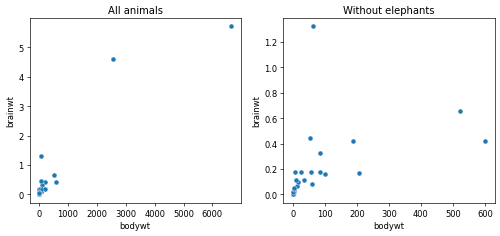


#### 2-4. 코끼리 두 마리를 제외했을 때 피어슨 상관계수는 크게 바뀌었지만 스피어만 상관계수는 거의 그대로임. 그 이유를 2-3 의 그래프를 근거로 설명하시오.

---

##### 답안 (이 셀을 더블클릭하여 아래에 작성)

- 피어슨 상관계수가 크게 바뀐 이유:
- 스피어만 상관계수가 거의 그대로인 이유:

---

## 문제 3. 순열 검정 직접 구현하기 (제한시간 20분)

- 질문: **육식 동물(`carni`)과 초식 동물(`herbi`)의 평균 수면 시간에는 차이가 있는가?**

#### 3-1. 육식 동물과 초식 동물의 수와 평균 수면 시간을 구하시오.

- 결과 열 이름은 `n`, `mean_sleep`, 평균은 소수점 둘째 자리까지

In [ ]:
two = None        # TODO: 육식과 초식 동물만 추출
summary = None    # TODO: vore 별 동물 수(n)와 평균 수면 시간(mean_sleep), 소수점 둘째 자리

print(summary)

**기대 출력**

```
        n  mean_sleep
vore                 
carni  19       10.38
herbi  32        9.51
```

#### 3-2. 순열 검정으로 유의확률을 구하시오.

- 관찰한 차이는 **육식 평균 - 초식 평균**
- 난수 생성기는 `np.random.default_rng(42)` 를 사용하고, 1만 번 반복할 것
- 유의확률은 소수점 셋째 자리까지

> **힌트**
> - 강의 자료의 펭귄 순열 검정과 같은 구조임
> - 섞은 배열에서 앞부분을 어느 집단으로 볼지 정해 두고, 관찰한 차이와 같은 방향으로 계산할 것

In [ ]:
carni = None      # TODO: 육식 동물의 수면 시간
herbi = None      # TODO: 초식 동물의 수면 시간

observed = None   # TODO: 육식 평균 - 초식 평균
sleep = None      # TODO: 두 집단의 값을 합친 배열
n_h = None        # TODO: 초식 동물의 수

rng = np.random.default_rng(42)
diffs = []
for _ in range(10000):
    shuffled = None          # TODO
    diffs.append(None)       # TODO: 섞은 뒤 두 집단의 평균 차이
diffs = np.array(diffs)

p_value = None    # TODO

print("관찰한 차이:", round(observed, 2))
print("유의확률:", round(p_value, 3))

**기대 출력**

```
관찰한 차이: 0.87
유의확률: 0.53
```

- 반복 순서에 따라 유의확률이 소수점 둘째 자리 정도 달라질 수 있음. 0.5 안팎이면 정답

#### 3-3. 섞어서 나온 차이(`diffs`)의 히스토그램을 그리고, 관찰한 차이의 위치에 세로선을 그리시오.

- 구간 수는 50, 세로선은 양쪽(관찰한 차이와 그 음수)에 빨간색으로
- 제목은 `Shuffled Differences (carni - herbi)`

In [ ]:
# 히스토그램과 세로선

**기대 출력**

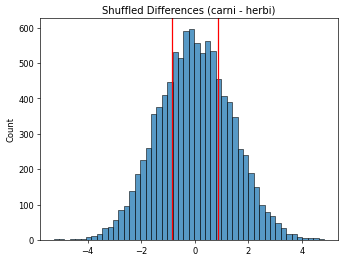


#### 3-4. t 검정으로 같은 질문을 검정하고, 순열 검정의 결과와 비교하시오.

- 두 집단의 분산이 같다고 가정할 것

In [ ]:
result = None    # TODO

print("t 검정 유의확률:", round(result.pvalue, 3))

**기대 출력**

```
t 검정 유의확률: 0.535
```

#### 3-5. 유의수준 0.05 에서 결론을 한 문장으로 쓰시오.

---

##### 답안 (이 셀을 더블클릭하여 아래에 작성)

- 결론:

---

## 문제 4. 유의확률과 함께 확인해야 할 것 (제한시간 8분)

#### 4-1. 충식 동물(`insecti`)과 초식 동물(`herbi`)의 수와 평균 수면 시간을 구하고, t 검정의 유의확률을 구하시오.

- 평균은 소수점 둘째 자리, 유의확률은 소수점 셋째 자리까지
- 두 집단의 분산이 같다고 가정할 것

In [ ]:
insecti = None    # TODO: 충식 동물의 수면 시간
herbi   = None    # TODO: 초식 동물의 수면 시간 (3-2 와 같음)

print("insecti:", len(insecti), "마리, 평균", round(insecti.mean(), 2))
print("herbi  :", len(herbi), "마리, 평균", round(herbi.mean(), 2))
print("유의확률:", None)    # TODO

**기대 출력**

```
insecti: 5 마리, 평균 14.94
herbi  : 32 마리, 평균 9.51
유의확률: 0.031
```

#### 4-2. 유의확률이 0.05 보다 작으므로 "충식 동물은 초식 동물보다 오래 잔다"는 결론을 내리려 함. 결론을 내리기 전에 함께 확인해야 할 것은 무엇인가?

> **힌트**
> - 충식 동물이 어떤 동물들인지 직접 출력해 볼 

In [ ]:
# 힌트를 확인하는 코드 작성


---

##### 답안 (이 셀을 더블클릭하여 아래에 2~3문장으로 작성)

- 함께 확인해야 할 것: